# Predicción de bajas voluntarias de empleados
### Proyecto Integrador Final – Prácticas Profesionalizantes I
Modelo de Red Neuronal Artificial (Keras) que estima la probabilidad de que un empleado deje la empresa.

In [1]:
# Importación de las librerías
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

# Semilla para que los resultados se puedan repetir
tf.keras.utils.set_random_seed(42)
os.makedirs('../img', exist_ok=True)
print('Librerías importadas de forma correcta')

Librerías importadas de forma correcta


### 1. Cargar los datos
Dataset público *IBM HR Analytics Employee Attrition* (datos ficticios creados por IBM).

In [2]:
datos = pd.read_csv('../data/empleados_ibm.csv')
print('Cantidad de registros y columnas: ', datos.shape)
print('Datos faltantes: ', datos.isnull().sum().sum())
datos.head()

Cantidad de registros y columnas:  (1470, 35)
Datos faltantes:  0


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


### 2. Análisis exploratorio

Distribución de la variable objetivo (Attrition)
Attrition
No     1233
Yes     237
Name: count, dtype: int64
Tasa de bajas:  16.1 %


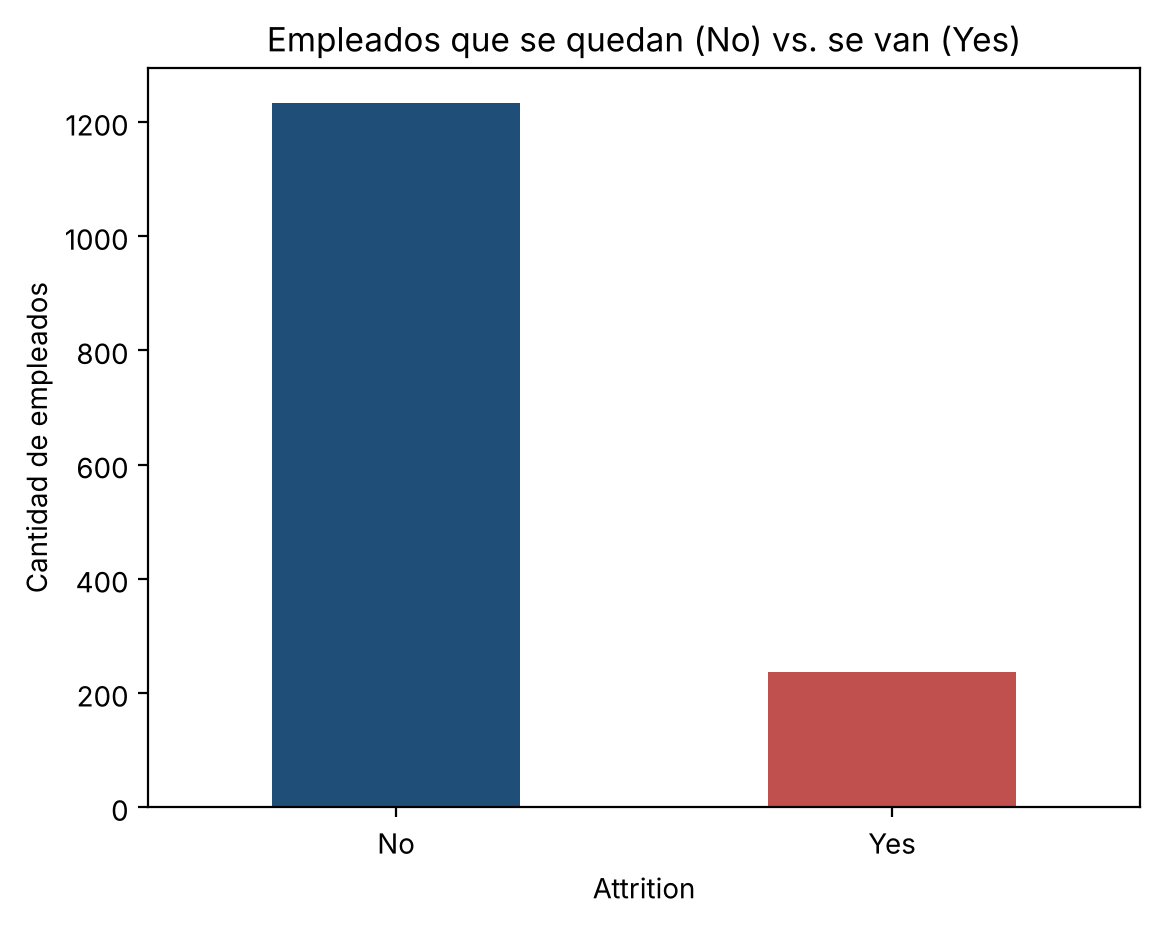

In [3]:
# ¿Cuántos empleados se fueron?
print('Distribución de la variable objetivo (Attrition)')
print(datos['Attrition'].value_counts())
print('Tasa de bajas: ', round((datos['Attrition'] == 'Yes').mean() * 100, 1), '%')

datos['Attrition'].value_counts().plot(kind='bar', color=['#1f4e79', '#c0504d'])
plt.title('Empleados que se quedan (No) vs. se van (Yes)')
plt.ylabel('Cantidad de empleados')
plt.xticks(rotation=0)
plt.savefig('../img/distribucion_bajas.png', bbox_inches='tight')
plt.show()

Tasa de bajas (%) según OverTime
OverTime
No     10.4
Yes    30.5
Name: Attrition, dtype: float64
-------------------------------------------
Tasa de bajas (%) según JobLevel
JobLevel
1    26.3
2     9.7
3    14.7
4     4.7
5     7.2
Name: Attrition, dtype: float64
-------------------------------------------
Tasa de bajas (%) según JobSatisfaction
JobSatisfaction
1    22.8
2    16.4
3    16.5
4    11.3
Name: Attrition, dtype: float64
-------------------------------------------


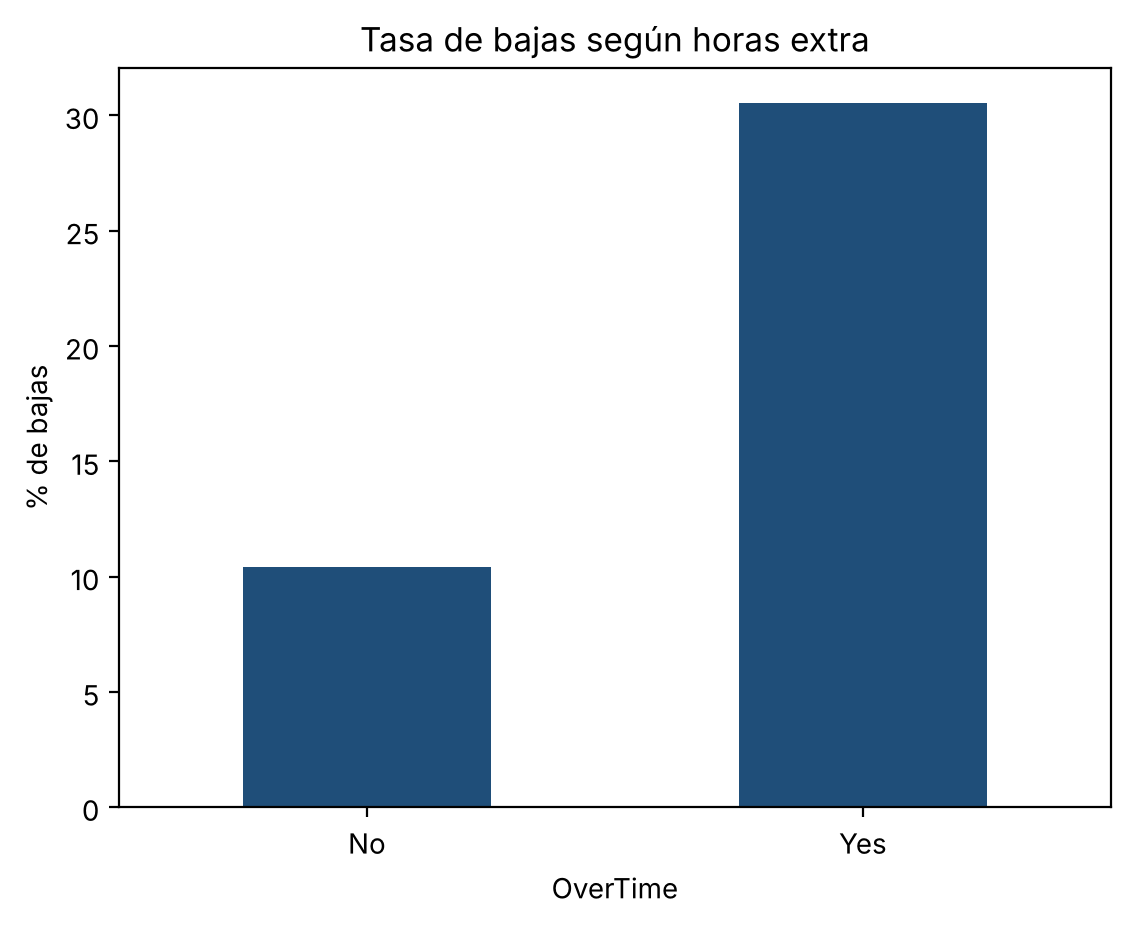

In [4]:
# Tasa de bajas según algunas variables
for variable in ['OverTime', 'JobLevel', 'JobSatisfaction']:
    tasa = datos.groupby(variable)['Attrition'].apply(lambda s: round((s == 'Yes').mean() * 100, 1))
    print('Tasa de bajas (%) según', variable)
    print(tasa)
    print('-------------------------------------------')

tasa_horas_extra = datos.groupby('OverTime')['Attrition'].apply(lambda s: (s == 'Yes').mean() * 100)
tasa_horas_extra.plot(kind='bar', color='#1f4e79')
plt.title('Tasa de bajas según horas extra')
plt.ylabel('% de bajas')
plt.xticks(rotation=0)
plt.savefig('../img/bajas_horas_extra.png', bbox_inches='tight')
plt.show()

### 3. Preparación de los datos
- Se convierten a 0/1 las columnas de texto que se usan.
- **Decisión ética:** no se usan edad (`Age`), género (`Gender`) ni estado civil (`MaritalStatus`) para evitar que el modelo discrimine por esas características (ver `docs/etica.md`).

In [5]:
# Convertir texto a números
datos['Attrition'] = datos['Attrition'].map({'Yes': 1, 'No': 0})
datos['OverTime'] = datos['OverTime'].map({'Yes': 1, 'No': 0})

# Variables predictoras
X = datos[[
    'OverTime',
    'MonthlyIncome',
    'JobLevel',
    'TotalWorkingYears',
    'YearsAtCompany',
    'YearsSinceLastPromotion',
    'JobSatisfaction',
    'EnvironmentSatisfaction',
    'WorkLifeBalance',
    'StockOptionLevel',
    'DistanceFromHome',
    'NumCompaniesWorked'
]]
# Variable objetivo
y = datos['Attrition']
print('Variables predictoras: ', X.shape[1])
X.head()

Variables predictoras:  12


,OverTime,MonthlyIncome,JobLevel,TotalWorkingYears,YearsAtCompany,YearsSinceLastPromotion,JobSatisfaction,EnvironmentSatisfaction,WorkLifeBalance,StockOptionLevel,DistanceFromHome,NumCompaniesWorked
0,1,5993,2,8,6,0,4,2,1,0,1,8
1,0,5130,2,10,10,1,2,3,3,1,8,1
2,1,2090,1,7,0,0,3,4,3,0,2,6
3,1,2909,1,8,8,3,3,4,3,0,3,1
4,0,3468,1,6,2,2,2,1,3,1,2,9


### 4. Dividir los datos en entrenamiento y prueba

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y   # mantiene el mismo % de bajas en ambos grupos
)
print('Registros para el entrenamiento: ', len(X_train))
print('Registros para la prueba: ', len(X_test))

Registros para el entrenamiento:  1176
Registros para la prueba:  294


### 5. Normalización de las variables

In [7]:
escalador = StandardScaler()
X_train_normalizado = escalador.fit_transform(X_train)
X_test_normalizado = escalador.transform(X_test)
print('Datos normalizados (primeros 3 registros)')
print(X_train_normalizado[:3].round(2))

Datos normalizados (primeros 3 registros)
[[-0.64  2.03  1.76  2.26 -0.67 -0.37 -0.65 -0.66  0.34  2.61 -0.9   1.33]
 [-0.64 -0.86 -0.99 -1.07 -0.83 -0.06  1.15  0.26  0.34  0.25 -0.9  -1.08]
 [-0.64  2.35  1.76  1.49  0.81  0.57  0.25 -1.58  0.34  0.25 -0.78  0.12]]


### 6. Construir la Red Neuronal Artificial
Clasificación binaria: la capa de salida usa `sigmoid` y devuelve una probabilidad entre 0 y 1.

In [8]:
modelo = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X.shape[1],)),
    tf.keras.layers.Dense(16, activation='relu'),
    tf.keras.layers.Dense(8, activation='relu'),
    tf.keras.layers.Dense(1, activation='sigmoid')
])
modelo.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 353 (1.38 KB)

 Trainable params: 353 (1.38 KB)

 Non-trainable params: 0 (0.00 B)

### 7. Compilación del modelo

In [9]:
modelo.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)
print('Modelo compilado de forma correcta')

Modelo compilado de forma correcta


### 8. Entrenar el modelo
Solo el 16% de los empleados se fue (datos desbalanceados). Con `class_weight` se le da más peso a los casos de baja para que el modelo no aprenda a decir siempre "se queda".

Peso de cada clase:  {0: 1.0, 1: 5.19}


Modelo entrenado de forma correcta


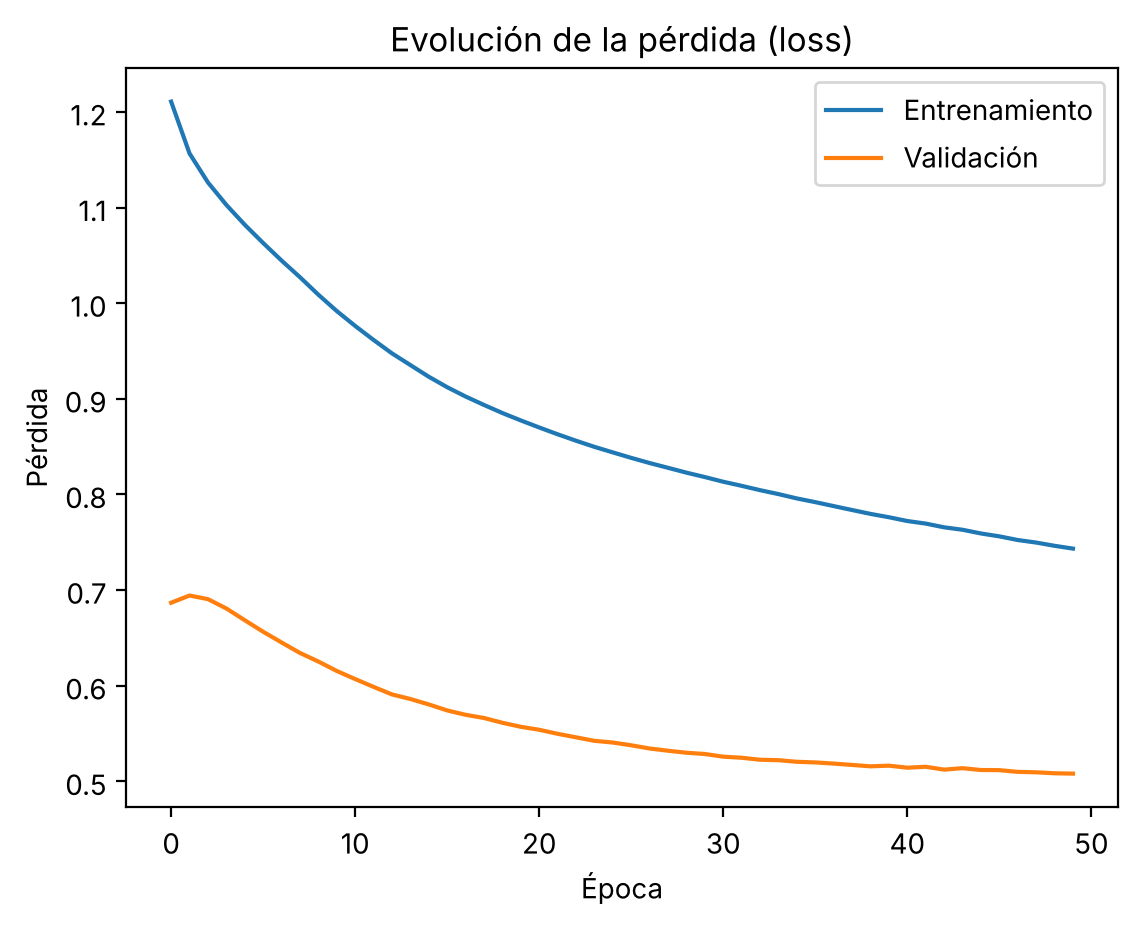

In [10]:
pesos_clases = {
    0: 1.0,
    1: float(round((y_train == 0).sum() / (y_train == 1).sum(), 2))
}
print('Peso de cada clase: ', pesos_clases)

historial = modelo.fit(
    X_train_normalizado,
    y_train,
    epochs=50,
    batch_size=32,
    validation_split=0.20,
    class_weight=pesos_clases,
    verbose=0
)
print('Modelo entrenado de forma correcta')

plt.plot(historial.history['loss'], label='Entrenamiento')
plt.plot(historial.history['val_loss'], label='Validación')
plt.title('Evolución de la pérdida (loss)')
plt.xlabel('Época')
plt.ylabel('Pérdida')
plt.legend()
plt.savefig('../img/historial_entrenamiento.png', bbox_inches='tight')
plt.show()

### 9. Evaluar el modelo con los datos de prueba
Además de la exactitud (accuracy) se mira el **recall** de la clase 1: de los empleados que realmente se fueron, cuántos detectó el modelo.

Pérdida:  0.51
Exactitud (accuracy):  75.5 %


Reporte de clasificación
              precision    recall  f1-score   support

Se queda (0)       0.94      0.76      0.84       247
   Se va (1)       0.37      0.74      0.49        47

    accuracy                           0.76       294
   macro avg       0.65      0.75      0.67       294
weighted avg       0.85      0.76      0.78       294



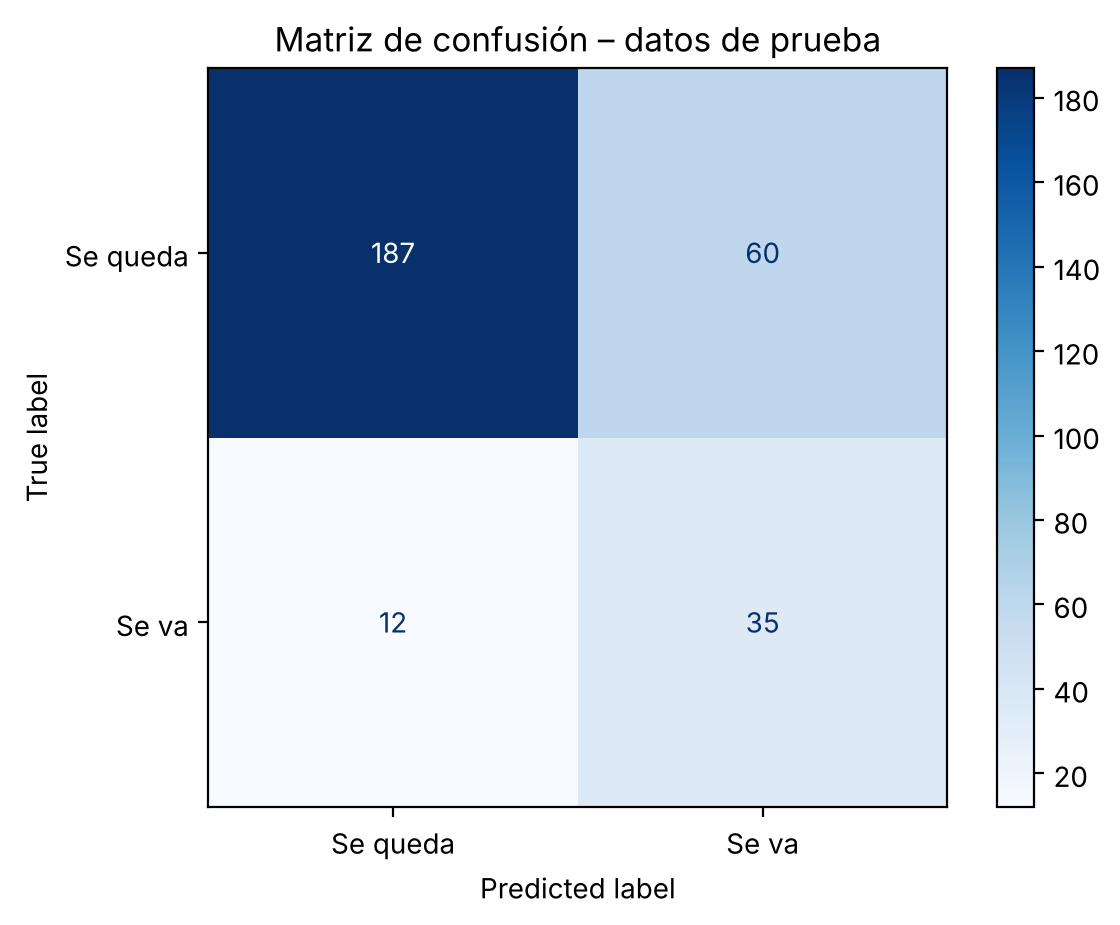

In [11]:
perdida, exactitud = modelo.evaluate(X_test_normalizado, y_test, verbose=0)
print('Pérdida: ', round(perdida, 2))
print('Exactitud (accuracy): ', round(exactitud * 100, 1), '%')

probabilidades = modelo.predict(X_test_normalizado, verbose=0)
predicciones = (probabilidades >= 0.5).astype(int).ravel()

print('Reporte de clasificación')
print(classification_report(y_test, predicciones, target_names=['Se queda (0)', 'Se va (1)']))

matriz = confusion_matrix(y_test, predicciones)
ConfusionMatrixDisplay(matriz, display_labels=['Se queda', 'Se va']).plot(cmap='Blues')
plt.title('Matriz de confusión – datos de prueba')
plt.savefig('../img/matriz_confusion.png', bbox_inches='tight')
plt.show()

### 10. Hacer una predicción con un nuevo empleado

In [12]:
nuevo_empleado = pd.DataFrame([{
    'OverTime': 1,
    'MonthlyIncome': 2500,
    'JobLevel': 1,
    'TotalWorkingYears': 2,
    'YearsAtCompany': 1,
    'YearsSinceLastPromotion': 0,
    'JobSatisfaction': 1,
    'EnvironmentSatisfaction': 2,
    'WorkLifeBalance': 2,
    'StockOptionLevel': 0,
    'DistanceFromHome': 20,
    'NumCompaniesWorked': 4
}])
nuevo_empleado_escalado = escalador.transform(nuevo_empleado)
probabilidad = modelo.predict(nuevo_empleado_escalado, verbose=0)[0][0]
print('Probabilidad de baja: ', round(probabilidad * 100, 1), '%')
if probabilidad >= 0.5:
    print('Riesgo ALTO: se sugiere una conversación de seguimiento con el empleado')
else:
    print('Riesgo BAJO')

Probabilidad de baja:  99.6 %
Riesgo ALTO: se sugiere una conversación de seguimiento con el empleado


### 11. Guardar el modelo

In [13]:
modelo.save('../modelo_bajas_entrenado.keras')
print('Modelo guardado exitosamente!!!')

Modelo guardado exitosamente!!!


### Anexo: ¿mejora el modelo si se agregan edad, género y estado civil?
Prueba para respaldar la decisión ética: se entrena la misma red agregando esas variables y se comparan los resultados.

In [14]:
def entrenar_y_evaluar(columnas):
    X_tr, X_te, y_tr, y_te = train_test_split(datos[columnas], y, test_size=0.20, random_state=42, stratify=y)
    esc = StandardScaler()
    X_tr = esc.fit_transform(X_tr)
    X_te = esc.transform(X_te)
    tf.keras.utils.set_random_seed(42)
    red = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(len(columnas),)),
        tf.keras.layers.Dense(16, activation='relu'),
        tf.keras.layers.Dense(8, activation='relu'),
        tf.keras.layers.Dense(1, activation='sigmoid')
    ])
    red.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    red.fit(X_tr, y_tr, epochs=50, batch_size=32, validation_split=0.20, class_weight=pesos_clases, verbose=0)
    pred = (red.predict(X_te, verbose=0) >= 0.5).astype(int).ravel()
    vp_queda, falsas, no_detectadas, detectadas = confusion_matrix(y_te, pred).ravel()
    return round((vp_queda + detectadas) / len(y_te) * 100, 1), detectadas, falsas

# Convertir las variables sensibles a números
datos['Gender_num'] = datos['Gender'].map({'Male': 1, 'Female': 0})
datos['Soltero'] = (datos['MaritalStatus'] == 'Single').astype(int)
datos['Casado'] = (datos['MaritalStatus'] == 'Married').astype(int)

variables_base = list(X.columns)
variables_con_sensibles = variables_base + ['Age', 'Gender_num', 'Soltero', 'Casado']

for nombre, columnas in [('Sin variables sensibles', variables_base), ('Con variables sensibles', variables_con_sensibles)]:
    exactitud_x, detectadas_x, falsas_x = entrenar_y_evaluar(columnas)
    print(nombre)
    print('  Exactitud: ', exactitud_x, '%  | Bajas detectadas: ', detectadas_x, 'de 47 | Falsas alarmas: ', falsas_x)

Sin variables sensibles
  Exactitud:  75.5 %  | Bajas detectadas:  35 de 47 | Falsas alarmas:  60


Con variables sensibles
  Exactitud:  77.6 %  | Bajas detectadas:  32 de 47 | Falsas alarmas:  51


### Conclusión
El modelo es un **prototipo académico**: sirve para priorizar conversaciones de retención, no para tomar decisiones automáticas sobre personas. Sus resultados deben interpretarse junto con el criterio de RRHH.